# Lab 4: Binary Classification and Cost-Sensitive Decision Making

**Course:** Machine Learning  
**Project:** Predicting Service Ticket Escalation  
**Dataset:** classification_escalation.csv

## Objective

The objective of this project is to build and evaluate binary
classification models for predicting whether a service ticket
will be escalated.

The project compares different classifiers, evaluates their
performance using multiple metrics, studies classification
thresholds, and considers the different costs of false
positive and false negative predictions.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [7]:
df = pd.read_csv("classification_escalation.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


In [8]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["escalated"].value_counts())

print("\nTarget Proportions:")
print(
    df["escalated"]
    .value_counts(normalize=True)
    .rename("proportion")
)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Missing Values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target Distribution:
escalated
0    714
1    186
Name: count, dtype: int64

Target Proportions:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


## 1. Understanding the Classification Problem

This is a binary classification problem because the target
variable has only two possible outcomes:

- 1: The service ticket is escalated.
- 0: The service ticket is not escalated.

The positive class is 1 (escalated).

The objective is to predict the probability that a ticket
will be escalated based on its characteristics.

Accuracy alone may be misleading because the dataset is imbalanced.

The majority-class baseline achieves approximately 79.56%
accuracy on the test set because 179 out of 225 test records
belong to the non-escalated class. Although this accuracy
appears relatively high, the model has zero recall for
escalated tickets because it never predicts the positive class.

Therefore, precision, recall, F1-score, and ROC-AUC are
also important evaluation metrics.

In [9]:
X = df.drop("escalated", axis=1)
y = df["escalated"]

print("Features:")
display(X.head())

print("\nTarget:")
print(y.head())

print("\nNumber of features:", X.shape[1])
print("Number of records:", X.shape[0])

Features:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months
0,9,7.7,low,web,21.6
1,2,6.1,high,web,21.8
2,1,2.5,medium,phone,28.8
3,7,5.3,low,email,52.5
4,4,7.1,medium,email,14.7



Target:
0    0
1    0
2    0
3    0
4    0
Name: escalated, dtype: int64

Number of features: 5
Number of records: 900


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (675, 5)
Testing features: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [11]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


In [12]:
models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),

    "KNN (k=15)": KNeighborsClassifier(
        n_neighbors=15
    )
}

print("Four classification models are ready.")

Four classification models are ready.


In [13]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

comparison_df = pd.DataFrame(results)

display(
    comparison_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,Linear Discriminant Analysis,0.8222,0.75,0.1957,0.3103,0.8090
3,KNN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


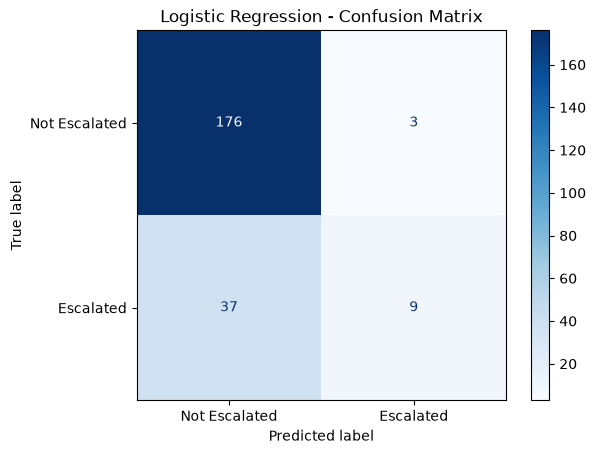

Confusion Matrix:
[[176   3]
 [ 37   9]]


In [14]:
logistic_model = trained_models["Logistic Regression"]

y_pred_logistic = logistic_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

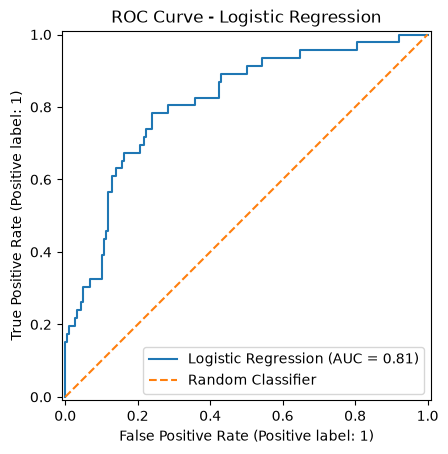

In [15]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [16]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (
        y_prob_logistic >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_threshold_pred,
        zero_division=0
    )

    cost = (5 * fn) + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "FP": fp,
        "FN": fn,
        "Total Cost": cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score,FP,FN,Total Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


Best Threshold:
Threshold      0.200000
Precision      0.428571
Recall         0.782609
F1-Score       0.553846
FP            48.000000
FN            10.000000
Total Cost    98.000000
Name: 0, dtype: float64

Minimum Cost: 98.0


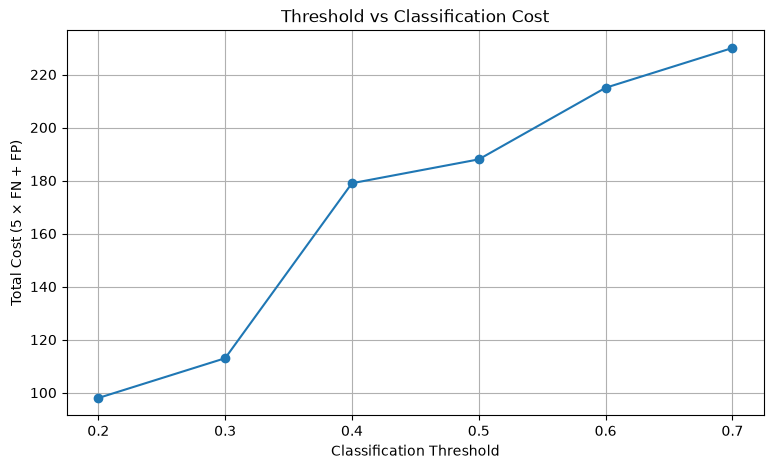

In [17]:
best_threshold_row = threshold_df.loc[
    threshold_df["Total Cost"].idxmin()
]

print("Best Threshold:")
print(best_threshold_row)

print("\nMinimum Cost:", best_threshold_row["Total Cost"])

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Cost"],
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Cost (5 × FN + FP)")
plt.title("Threshold vs Classification Cost")
plt.xticks(thresholds)
plt.grid(True)

plt.show()

In [18]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best K:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)

knn_cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    knn_cv_results[
        [
            "param_classifier__n_neighbors",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].round(4)
)

Best K: {'classifier__n_neighbors': 5}
Best Cross-Validation F1: 0.24329611908559276


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


## 2. Bayesian Reasoning in Ticket Escalation

Bayes' theorem explains how prior knowledge is updated
when new evidence becomes available.

P(E|X) = P(X|E) × P(E) / P(X)

Where:

- Prior: P(E) is the initial probability that a ticket
  will be escalated before examining its characteristics.
- Likelihood: P(X|E) is the probability of observing
  particular ticket characteristics given escalation.
- Evidence: P(X) is the probability of observing those
  characteristics across all tickets.
- Posterior: P(E|X) is the updated probability of
  escalation after observing the ticket characteristics.

In this project, the prior probability of escalation
is approximately 20.67%.

The classifier estimates the probability of escalation
based on the ticket's features.

In [19]:
probability_escalated = 0.30

false_positive_cost = 1
false_negative_cost = 5

cost_escalate = (
    (1 - probability_escalated) * false_positive_cost
)

cost_not_escalate = (
    probability_escalated * false_negative_cost
)

print("Expected cost of escalating:", cost_escalate)

print("Expected cost of not escalating:", cost_not_escalate)

if cost_escalate < cost_not_escalate:
    print("\nDecision: Escalate the ticket.")
else:
    print("\nDecision: Do not escalate the ticket.")

optimal_threshold = (
    false_positive_cost /
    (false_positive_cost + false_negative_cost)
)

print("\nCost-sensitive threshold:", optimal_threshold)

Expected cost of escalating: 0.7
Expected cost of not escalating: 1.5

Decision: Escalate the ticket.

Cost-sensitive threshold: 0.16666666666666666


## 3. Model Recommendation and Conclusion

### Recommendation

The classification experiment demonstrates that selecting a
model requires considering the consequences of prediction
errors rather than relying exclusively on accuracy.

The dataset contains 900 synthetic service tickets, of which
186 (20.67%) are escalated and 714 (79.33%) are not escalated.
This class imbalance makes accuracy alone potentially
misleading. For example, the majority-class baseline achieves
approximately 79.56% accuracy but has zero recall for
escalated tickets. Therefore, it fails to identify the
positive class entirely.

Logistic Regression and Linear Discriminant Analysis
achieved the strongest overall results among the evaluated
classifiers. Both obtained approximately 82.22% accuracy,
75% precision, 19.57% recall, 0.31 F1-score, and ROC-AUC
above 0.80. KNN with k=15 achieved lower recall and F1-score.
The majority baseline was useful for demonstrating why a
simple accuracy comparison is insufficient.

The threshold experiment demonstrates the importance of
decision-making. At the default threshold of 0.50, the
Logistic Regression model misses many escalated tickets.
Lowering the threshold increases recall because more tickets
are classified as escalated. At a threshold of 0.20, recall
increases to approximately 78.26%, with 10 false negatives
and 48 false positives. Its total illustrative cost is 98,
calculated using 5 × FN + FP. This is the lowest cost among
the six evaluated thresholds.

I recommend Logistic Regression with a threshold of 0.20
as an initial candidate for further evaluation. This choice
prioritizes identifying escalated tickets because missing
an escalation is five times more costly than an unnecessary
escalation. The theoretical cost-sensitive threshold is
approximately 0.167, assuming calibrated probabilities and
the specified error costs.

Cross-validation selected k=5 as the best KNN configuration
among the tested values. However, this does not make KNN
the best deployment choice based on the current results.

There are important limitations. The dataset is synthetic,
and its patterns may not represent real service operations.
Furthermore, selecting the threshold using test-set costs
can produce an optimistic estimate if the same test set is
repeatedly used for tuning. A separate validation set or
nested evaluation should be used for final threshold
selection, leaving an untouched test set for final reporting.

Before deployment, the model should be tested on real
historical tickets, probability calibration should be
checked, and performance should be monitored over time.
Human review, privacy protection, fairness assessment,
and transparency are also necessary. The model should
support service personnel rather than automatically
making consequential decisions without oversight.

## 3. Answers to Assignment Questions

### 1. Why is accuracy alone potentially misleading?

Accuracy can be misleading because the dataset is imbalanced.
A model can predict every ticket as non-escalated and still
achieve approximately 79.56% test accuracy while identifying
zero escalated tickets. Therefore, recall, precision, F1-score,
and ROC-AUC are also necessary.

### 2. Which classifier has the strongest recall and precision/F1?

According to the model comparison results, Logistic Regression
and Linear Discriminant Analysis achieve the strongest
recall, precision, and F1-score among the evaluated models.
Their performance is tied on these metrics.

### 3. What happens when the classification threshold is lowered?

Lowering the threshold makes the classifier more likely to
predict escalation. This generally increases recall and
reduces false negatives, but can increase false positives
and decrease precision.

### 4. Which threshold minimizes the illustrative cost?

The threshold of 0.20 produces the lowest evaluated cost
among the six tested thresholds.

Cost = (5 × FN) + FP = (5 × 10) + 48 = 98.

Repeatedly selecting a threshold using the test set can
produce an optimistic estimate because the test data is
being used for model selection rather than independent
final evaluation.

### 5. Explain prior, likelihood, posterior, and evidence.

- Prior: Initial probability of escalation before examining
  ticket characteristics.
- Likelihood: Probability of observing the ticket
  characteristics given that the ticket is escalated.
- Evidence: Overall probability of observing those
  characteristics.
- Posterior: Updated probability of escalation after
  considering the ticket characteristics.

### 6. Calculate the expected costs when P(escalated|x) = 0.30.

Expected cost of escalating:

(1 - 0.30) × 1 = 0.70

Expected cost of not escalating:

0.30 × 5 = 1.50

Since 0.70 is less than 1.50, escalating is the better
decision.

The cost-sensitive threshold is:

1 / (1 + 5) = 0.1667

### 7. Which model would you recommend for deployment?

Logistic Regression with a threshold of 0.20 is an initial
candidate because missing an escalated ticket is more
expensive than unnecessarily escalating one.

Before deployment, the model requires testing on real
historical data, probability calibration, fairness
assessment, performance monitoring, and human oversight.